# **Introducción a MNE-Python** 🧠👨‍💻
# *Cuaderno 1: exploración y preparación de datos EEG* 🔎#

**Tutorial exploratorio de procesamiento de datos de EEG en Python (en construcción).**

Este cuaderno documenta un proceso de aprendizaje y desarrollo metodológico orientado al procesamiento de EEG mediante **Python y MNE-Python**, con énfasis en la reproducibilidad, la ciencia abierta y la exploración de herramientas para el análisis de datos neurofisiológicos.

El material tiene un propósito **educativo y exploratorio**. No constituye un pipeline EEG validado, un protocolo metodológico universal ni una guía normativa de análisis. Las decisiones de procesamiento deben interpretarse según el objetivo de cada análisis y contrastarse con la literatura científica y la documentación de las herramientas utilizadas.

El cuaderno se desarrolla como un recurso de aprendizaje abierto y progresivo.  **Para consultar el contexto metodológico, estado del proyecto, fuentes de referencia, datos, licencias y demás consideraciones, véase el `README.md` del repositorio. Este notebook fue desarrollado utilizando MNE-Python 1.13.2, Python 3.12 y sus principales dependencias. Las versiones completas de los paquetes utilizados se encuentran especificadas en el archivo `requirements.txt`.**


## 0. Alcance, datos de ejemplo y reproducibilidad

Este tutorial es introductorio. MNE-Python permite construir flujos de trabajo completos para EEG/MEG, pero no existe un único preprocesamiento que sea correcto para todas las preguntas de investigación. Las decisiones sobre filtrado, referencia, detección de canales/segmentos malos, corrección de artefactos, segmentación y análisis espectral deben justificarse de acuerdo con el objetivo analítico y documentarse. La literatura muestra que decisiones aparentemente pequeñas de preprocesamiento pueden modificar los resultados posteriores.

Los ejemplos utilizan el archivo **`data/sample_eeg.edf`**, incluido con este tutorial, que contiene datos EEG sintéticos generados para fines pedagógicos basado en un registro tomado a traves del software `Neuroguide` y no corresponden a una persona real, asi como un registro de la base de datos de Schalk (2009) extraido por medio del mismo paquete de MNE. En un repositorio reproducible conviene mantener separados el archivo original, las copias procesadas y los resultados exportados. También es recomendable conservar la versión de MNE-Python y de las principales dependencias utilizadas para ejecutar el cuaderno. MNE destaca precisamente que los scripts constituyen un registro de las operaciones realizadas y facilitan la reproducción y auditoría del análisis.

## 1.Configuración inicial y montaje

Se instalan las dependencias del proyecto especificadas en el archivo requirements.txt, que documenta las versiones de las librerías utilizadas para desarrollar este cuaderno. Esto facilita la reproducibilidad del entorno de análisis.

In [3]:
#%pip install -r requirements.txt

Se importan las librerias. En este caso, se selecciona el backend `matplotlib` para el navegador de MNE, mediante `mne.viz.set_browser_backend("matplotlib")`. Esto hace que funciones como `raw.plot()` utilicen el navegador de MNE basado en Matplotlib.

La forma en que estas figuras se muestran depende, además, del backend gráfico utilizado por Matplotlib. Dentro de un cuaderno Jupyter, con el modo `inline`, las figuras se muestran integradas en el propio cuaderno y la interactividad puede ser limitada. En cambio, mediante un backend gráfico como Qt, las figuras pueden abrirse en ventanas independientes y conservar una mayor interactividad, incluida la interacción con visualizaciones 3D.

In [4]:
import matplotlib.pyplot as plt
import mne
mne.viz.set_browser_backend("matplotlib")

Using matplotlib as 2D backend.


Empecemos por leer nuestro archivo. MNE soporta la lectura de diversos formatos tales como:
       `BrainVision (.vhdr, .vmrk, .eeg), European data format (.edf), BioSemi data format (.bdf), General data format (.gdf), Neuroscan CNT (.cnt), EGI simple binary (.egi),EGI MFF (.mff), EEGLAB files (.set, .fdt), Nicolet (.data), eXimia EEG data (.nxe), Persyst EEG data (.lay, .dat), Nihon Kohden EEG data (.eeg, .21e, .pnt, .log), XDF data (.xdf, .xdfz)`
       
De acuerdo al tipo de archivo, habrá un método para lectura. En este caso, manejamos un archivo .edf por lo que el método utilizado será `read_raw_edf`. Para ver la información básica del archivo, usamos `.info`. Para una información muchísimo más detallada se puede usar `raw.__dict__`. Para conocer todos los métodos asociados, puedes usar `dir`, ejemplo `dir(raw)` y para conocer en detalle sobre un método, con el signo de interrogación, ejemplo: `raw.plot_psd?`. También en la página web del paquete podrás encontrar más información de cada método.

Por otro lado, el uso de `preload=True` permite precargar a la memoria para manipulación de datos de manera rapida. Por defecto MNE no lee los datos completos, así que con esto nos aseguramos. `verbose=False` evita que salga información que podría no ser tan necesaria, pero es opcional.

In [5]:
raw = mne.io.read_raw_edf("data/sample_eeg.edf", preload=True, verbose=False)
raw.info

<Info | 8 non-empty values
 bads: []
 ch_names: FP1-LE, FP2-LE, F3-LE, F4-LE, C3-LE, C4-LE, P3-LE, P4-LE, O1-LE, ...
 chs: 19 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 125.0 Hz
 meas_date: 1985-01-01 00:00:00 UTC
 nchan: 19
 projs: []
 sfreq: 250.0 Hz
 subject_info: <subject_info | his_id: >
>

Como refieren Newman et al. (2020) y la documentación de MNE, podemos explorar las características generales del registro EEG mediante diferentes herramientas:

**a)** Por ejemplo, podemos calcular la duración del registro a partir del número de muestras y la frecuencia de muestreo. Newman et al. (2020) ilustran este procedimiento mediante el siguiente código: `scan_durn = raw._data.shape[1] / raw.info['sfreq']`.

**b)** Otra opción es consultar los metadatos disponibles mediante `raw.info.keys()`, entre cuyas claves podrían encontrarse algunas de las más importantes, como `sfreq` (frecuencia de muestreo, en Hz), `ch_names` (nombres de los canales), `bads` (canales marcados como defectuosos), `highpass` y `lowpass` (límites de frecuencia registrados en los metadatos) y `line_freq` (frecuencia eléctrica de la red, si se conoce). Se puede acceder a estos valores mediante la clave correspondiente entre corchetes, por ejemplo: `raw.info["sfreq"]`, `raw.info["ch_names"]` o `raw.info["bads"]`.

**c)** También podemos obtener un resumen descriptivo de los datos con `raw.describe()`, que permite inspeccionar características estadísticas de los canales, como sus valores mínimos, máximos y media, así como otros indicadores disponibles según el tipo de canal y los datos registrados.

Estas no son las únicas opciones disponibles. Por ello, es recomendable consultar la [documentación oficial de MNE](https://mne.tools/stable/) para conocer otras herramientas y profundizar en las posibilidades de exploración de los datos.

In [6]:
scan_durn = raw._data.shape[1] / raw.info['sfreq']
#Adaptado al español de Newman et al. (2020)
print('Duración de registro EEG = ', scan_durn, 's, o', round(scan_durn / 60, 2), 'min.')
#Metadatos
print(raw.info.keys())
print(raw.describe())

Duración de registro EEG =  61.0 s, o 1.02 min.
dict_keys(['acq_pars', 'acq_stim', 'ctf_head_t', 'description', 'dev_head_t', 'dev_ctf_t', 'dig', 'experimenter', 'utc_offset', 'device_info', 'file_id', 'highpass', 'hpi_subsystem', 'kit_system_id', 'helium_info', 'line_freq', 'lowpass', 'meas_date', 'meas_id', 'proj_id', 'proj_name', 'subject_info', 'xplotter_layout', 'gantry_angle', 'bads', 'chs', 'comps', 'events', 'hpi_meas', 'hpi_results', 'projs', 'proc_history', 'custom_ref_applied', 'sfreq', 'ch_names', 'nchan'])
<RawEDF | sample_eeg.edf, 19 x 15250 (61.0 s), ~2.2 MiB, data loaded>
ch  name    type  unit        min         Q1     median         Q3        max
 0  FP1-LE  EEG   µV       -52.02     -11.76       0.66      12.65     112.08
 1  FP2-LE  EEG   µV       -51.07     -11.89       0.17      12.16     105.55
 2  F3-LE   EEG   µV       -56.63     -12.04       0.29      12.41      98.28
 3  F4-LE   EEG   µV       -50.40     -12.10      -0.20      12.44      82.54
 4  C3-LE   EEG

Saber qué información tenemos a disposición en el archivo nos permite ser capaces de hacer la manipulación de los datos necesarios y modificaciones que se requieran. Podemos saber cuántos canales tenemos, los filtros, si hay información de EOG o ECG disponible, canales malos, etc. Esto nos será de utilidad, pero ahora...miremos una vista previa de lo que tenemos: utilicemos `raw.plot` para graficar los datos brutos.

En este caso, se utiliza `scalings=dict(eeg=50e-6)` para ajustar la escala visual de las señales EEG. Este valor corresponde a 50 µV y permite que las variaciones de amplitud se visualicen de forma más clara en el gráfico, sin modificar los datos originales. En este contexto, el valor representa una amplitud de referencia de ±50 µV alrededor de cero, es decir, un rango de 100 µV pico a pico. Este rango resulta pertinente considerando que, típicamente, las señales EEG presentan amplitudes pico a pico de entre 10 y 100 µV (Lou et al., 2026). También puede utilizarse `scalings="auto"`, que permite a MNE determinar automáticamente los factores de escala de visualización a partir del percentil 99,5 de los datos correspondientes a cada tipo de canal.

**Nota**:  Al visualizar figuras de MNE dentro de este cuaderno, puede ocurrir que una misma figura aparezca más de una vez debido al funcionamiento de la visualización automática de Jupyter. Por esta razón, `plt.show()` puede utilizarse de forma explícita para controlar la visualización y evitar que la figura se muestre nuevamente de manera automática. La elección del entorno de visualización es independiente de este aspecto. Con la configuración habitual de Matplotlib, las figuras se muestran dentro del cuaderno; si se desea una visualización externa e interactiva, especialmente para gráficos 3D, puede utilizarse: `%matplotlib qt`antes de ejecutar cualquier código con una figura. En ese caso, las figuras se abrirán en ventanas independientes. Para volver a la visualización integrada en el cuaderno, puede utilizarse nuevamente `%matplotlib inline`

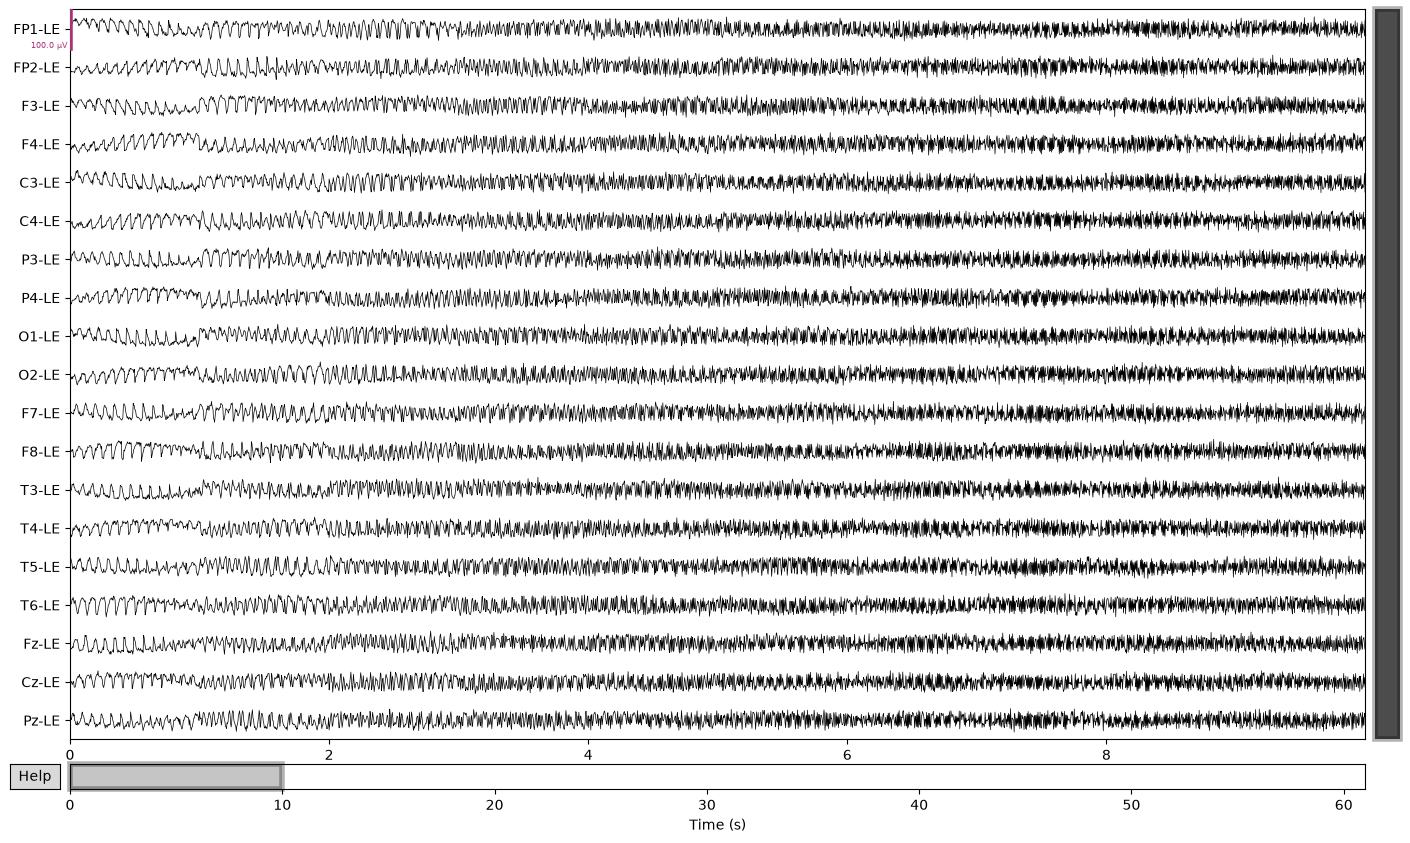

In [7]:
raw.plot(scalings=dict(eeg=50e-6), show=True)
plt.show()

Ahora conozcamos donde se ubican los electrodos en la cabeza de forma gráfica usando `raw.plot_sensors`. Además, queremos conocer el nombre de cada electrodo en la gráfica por lo que agregamos `show_names=True` (utilizamos un bloque `try-except` para capturar posibles errores durante la ejecución)

In [8]:
try:
    raw.plot_sensors(show_names=True)

except RuntimeError as e:
    print(e)

No valid channel positions found


Si tuviste un error `RuntimeError: No valid channel positions found` es porque precisamente el archivo, como tiende a ocurrir, puede no presentar la información de la ubicación de los sensores en la cabeza. Es posible que dentro de la información del archivo más arriba, en la sección `Digitized points` apareciera `Not available`. Si bien “puntos digitalizados” suena diferente a electrodos, se refiere precisamente a esos puntos de referencia (esto es, según *Newman et al., 2020*, dado que algunos investigadores utilizan la digitalización de los sensores directamente en la cabeza en vez de posiciones estandar). 

Teniendo esto en cuenta, es importante establecer el montaje que utilizamos. En este caso, usamos el sistema 10-20, por lo que a través del método `set_montage` se coloca `colin27_1020` que en versiones anteriores correspondia a `standard_1020`.

In [9]:
#Los nombres de los montajes pueden variar en distintas versiones
try:
    raw.set_montage('colin27_1020')
    
except ValueError as e:
    print(f"{e}")

DigMontage is only a subset of info. There are 19 channel positions not present in the DigMontage. The channels missing from the montage are:

['FP1-LE', 'FP2-LE', 'F3-LE', 'F4-LE', 'C3-LE', 'C4-LE', 'P3-LE', 'P4-LE', 'O1-LE', 'O2-LE', 'F7-LE', 'F8-LE', 'T3-LE', 'T4-LE', 'T5-LE', 'T6-LE', 'Fz-LE', 'Cz-LE', 'Pz-LE'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.


Si tuviste otro error con respecto al `DigMontage` es porque puede que la información registrada de los electrodos se encuentre referenciada de otra manera. Por ejemplo: 'FP1-LE', 'FP2-LE', 'F3-LE', 'F4-LE', 'C3-LE', 'C4-LE', etc. Esto dificulta el montaje en el formato que maneja MNE. Comprueba el nombre de tus canales con `raw.info["ch_names"]`

In [10]:
raw.info["ch_names"]

['FP1-LE',
 'FP2-LE',
 'F3-LE',
 'F4-LE',
 'C3-LE',
 'C4-LE',
 'P3-LE',
 'P4-LE',
 'O1-LE',
 'O2-LE',
 'F7-LE',
 'F8-LE',
 'T3-LE',
 'T4-LE',
 'T5-LE',
 'T6-LE',
 'Fz-LE',
 'Cz-LE',
 'Pz-LE']

Con el fin de renombrar los canales, es importante que ejecutemos las siguientes líneas de código, las cuales están diseñadas para buscar la información de los canales y renombrarlos. 

En el diccionario `mapping` alojaremos los canales originales y sus nuevos nombres, los cuales serán los mismos manejados a nivel general: **Fp1, Fp2, F3, F4** etc. Dado que puede haber casos donde los originales estén en mayúsculas, las líneas después del diccionario están diseñadas para cambiar a minúscula en los casos como **Fp1, Fp2, Fz, Pz y Cz**. Este es un paso importante en caso que el archivo tenga estas características que no permitan hacer el montaje sin antes renombrar los canales.

**Nota importante**. Siempre es importante que compruebes antes el nombre de tus canales. Las siguientes líneas están diseñadas para el caso de los nombres anteriormente reseñados, ejemplo: T3-LE, pero no funcionaría si el electrodo tuviera un nombre tipo EEG T3-LE. En este caso, una pequeña variación del código sería suficiente.

In [11]:
mapping = {}

for ch in raw.info["ch_names"]:
    name = ch.split("-")[0]
    
    if name[1].isupper():
        name = name[0] + name[1].lower() + name[2:]
    
    mapping[ch] = name

raw.rename_channels(mapping)

raw.info["ch_names"]

['Fp1',
 'Fp2',
 'F3',
 'F4',
 'C3',
 'C4',
 'P3',
 'P4',
 'O1',
 'O2',
 'F7',
 'F8',
 'T3',
 'T4',
 'T5',
 'T6',
 'Fz',
 'Cz',
 'Pz']

Con los nuevos canales nombrados correctamente, podemos ahora hacer el montaje en caso de que no se haya podido hacer. Puedes notar que ahora aparecerán como digitalizados los canales de nuestro archivo en **Digitalized points**. Es posible que a la información básica se agregue ahora también el nombre del archivo y el tiempo de la grabación (si bien esto es posible conocerlo también de otras maneras).

*Nota.* Recuerda que puede haber variaciones de montaje. Consulta la información disponible en la página de MNE.

In [12]:
#Las opciones de montaje pueden cambiar con versiones futuras. 
raw.set_montage('colin27_1020')

<RawEDF | sample_eeg.edf, 19 x 15250 (61.0 s), ~2.2 MiB, data loaded>

¿Porque se muestran mas puntos de lo que aparecen en canales? En el caso anterior dice 22 puntos, y son 19 canales. Recuerda que se ajusta a una ubicación estandar que se maneja desde el EEG. Comprobemos exactamente estos puntos de referencia usando `raw.info['dig']`.

In [13]:
raw.info['dig']

[<DigPoint |        LPA : (-82.5, -0.0, 0.0) mm     : head frame>,
 <DigPoint |     Nasion : (0.0, 114.0, 0.0) mm      : head frame>,
 <DigPoint |        RPA : (82.5, 0.0, -0.0) mm      : head frame>,
 <DigPoint |     EEG #1 : (-30.9, 114.6, 27.9) mm   : head frame>,
 <DigPoint |     EEG #3 : (28.4, 115.3, 27.7) mm    : head frame>,
 <DigPoint |    EEG #16 : (-71.9, 73.1, 25.8) mm    : head frame>,
 <DigPoint |    EEG #18 : (-51.8, 86.7, 78.7) mm    : head frame>,
 <DigPoint |    EEG #20 : (-1.2, 93.3, 102.6) mm    : head frame>,
 <DigPoint |    EEG #22 : (50.3, 87.4, 77.3) mm     : head frame>,
 <DigPoint |    EEG #24 : (71.4, 74.5, 25.1) mm     : head frame>,
 <DigPoint |    EEG #40 : (-67.1, 23.4, 104.5) mm   : head frame>,
 <DigPoint |    EEG #42 : (-1.4, 27.6, 140.2) mm    : head frame>,
 <DigPoint |    EEG #44 : (65.3, 23.6, 103.7) mm    : head frame>,
 <DigPoint |    EEG #62 : (-55.0, -44.2, 99.9) mm   : head frame>,
 <DigPoint |    EEG #64 : (-1.7, -45.2, 126.7) mm   : head fra

Como puedes ver, además de los 19 canales existen digitalizados tres puntos: LPA, Nasion y RPA. Estos se refieren a las posiciones Preauricular izquierda (Left Pre-Auricular o LPA), Preauricular derecha (Right Pre-Auricular o RPA) e intersección de la nariz (Nasion) que son puntos referenciales en el montaje estándar. Ahora bien, los números que ves en el paréntesis son coordenadas. Como menciona Newman et al., 2020 la ubicación se establece de acuerdo a un conjunto de coordenadas cartesianas ( x , y , z ) orientadas por los puntos ya mencionados: puente de la nariz y los canales auditivos izquierdo y derecho. Puedes ver el ejemplo que dan los autores aquí:  

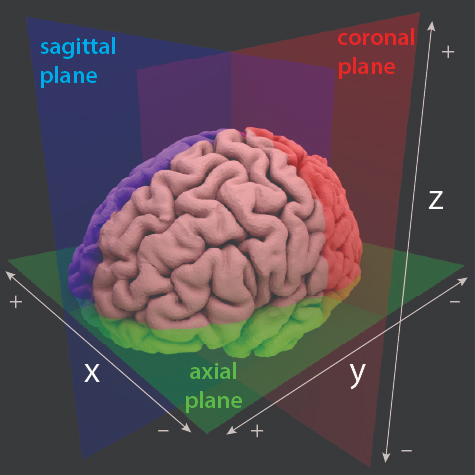 

**Fuente:** Newman, A. J., et al. (2020). *MRI_ax_sag_cor.jpg* [Imagen]. En *Neural Data Science in Python*. [Repositorio original](https://github.com/neural-data-science/NESC_3505_textbook/blob/master/7-eeg/images/MRI_ax_sag_cor.jpg). Licencia Creative Commons CC BY-NC 4.0. Se reproduce sin cambios.

Con los puntos ya establecidos, es posible establecer la posición de los sensores de la cabeza lo cual podría permitirnos hacer otro tipo de procesamientos si queremos saber ubicaciones especificas o con gráficas. 

¡Intentemos nuevamente ver los sensores ahora!

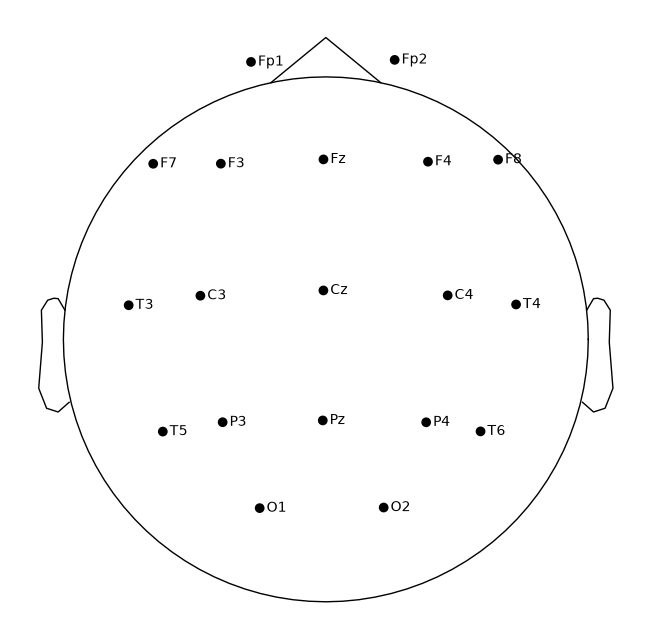

In [14]:
raw.plot_sensors(show_names=True)
plt.show()

¿Los electrodos parecen fuera de la cabeza? En realidad, la esfera(cabeza) es un modelo. Podemos ajustarlo para apoyarnos visualmente, colocando las coordenadas. Para el caso anterior podemos usar por ejemplo 0.00, 0.02, 0.02, 0.100 o 0.00, 0.02, 0.03, 0.112. Usemos las primeras y miremos el resultado.

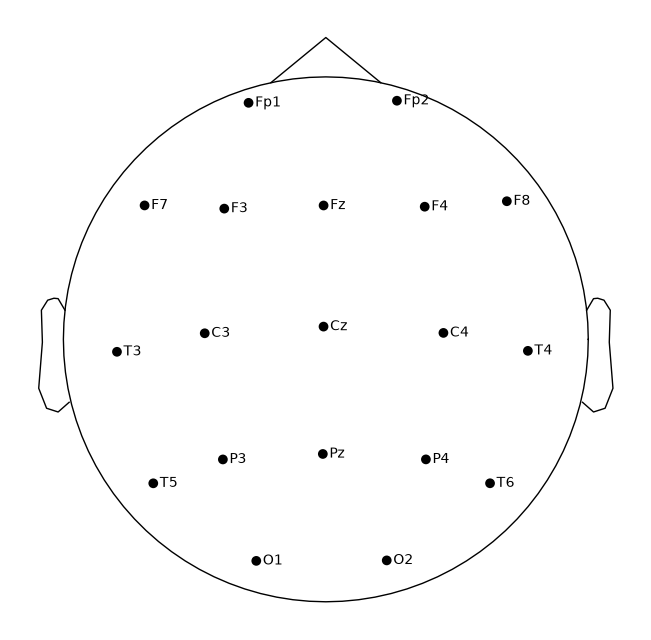

In [15]:
raw.plot_sensors(show_names=True, sphere=(0.00, 0.02, 0.02, 0.100))
plt.show()

Ahora, como prueba inicial, podemos visualizar de forma general el contenido frecuencial del archivo y observar cómo se diferencian espacialmente los electrodos. De acuerdo con la documentación de MNE, mediante el método `compute_psd().plot()` podemos calcular y visualizar la **Densidad Espectral de Potencia (DEP; en inglés, Power Spectral Density o PSD)**. Esta medida permite conocer cómo se distribuye la potencia de una señal a través de las distintas frecuencias y, por tanto, identificar los rangos de frecuencia en los que se concentra una mayor o menor potencia. En este sentido, Luengas y Toloza (2020) la describen como "una función matemática que da a conocer la distribución de la potencia de dicha señal sobre las distintas frecuencias en donde está formada. Así, se puede establecer el rango de frecuencias donde se concentran las variaciones de potencia"(p.4). 

La visualización del PSD puede realizarse incluso sin haber establecido previamente el montaje; sin embargo, en ese caso MNE no dispone de la información espacial necesaria para representar los electrodos gráficamente. Por ello, una vez asignado correctamente el montaje, la visualización interactiva del PSD permite seleccionar determinados rangos de frecuencia y observar, además del espectro, la distribución espacial de la potencia sobre la cabeza mediante topomapas. Esto permite pasar de una representación general de la potencia por frecuencia a una representación espacial de cómo dicha potencia se distribuye entre los diferentes electrodos.

En un archivo `.py`, esta visualización puede explorarse de forma interactiva, seleccionando distintos fragmentos del espectro para observar la distribución espacial correspondiente a los rangos de frecuencia seleccionados.

Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


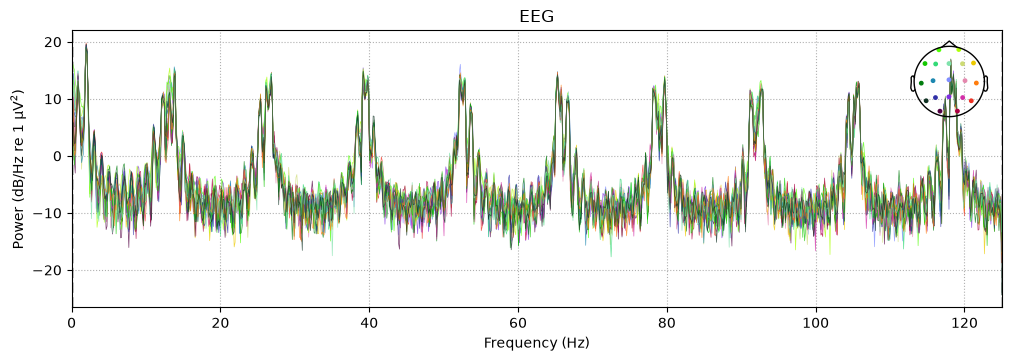

In [16]:
raw.compute_psd().plot(sphere=(0.00, 0.02, 0.02, 0.100))
plt.show()

El método anterior nos permite visualizar la PSD de forma general. Para obtener los valores de potencia como datos, podemos utilizar directamente `compute_psd()`, especificando el rango de frecuencias de interés mediante los criterios mínimo (`fmin`) y máximo (`fmax`). Posteriormente, con `to_data_frame()`, podemos convertir los resultados en una tabla para facilitar su consulta y posterior procesamiento. Estos datos también pueden exportarse a Excel, procedimiento que veremos más adelante.

Es importante recordar que, como se explicó anteriormente, la asignación del montaje mediante `set_montage()` no es necesaria para calcular la PSD, ya que esta se obtiene directamente a partir de las señales registradas en cada canal. En este punto, el montaje ya ha sido establecido porque necesitamos la información espacial de los electrodos para las visualizaciones topográficas realizadas previamente y para cualquier procedimiento posterior que requiera representar los resultados según su ubicación sobre la cabeza.

In [17]:
# Se calcula la densidad espectral de potencia (PSD) entre 0 y 4 Hz, correspondiente a la banda delta (δ) del EEG.
h=raw.compute_psd(fmin=0.0, fmax=4.0)

# Se convierte el resultado en una tabla de datos.
h.to_data_frame()

Effective window size : 8.192 (s)


,freq,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,F7,F8,T3,T4,T5,T6,Fz,Cz,Pz
0,0.000000,9.032120e-12,2.388834e-12,3.769715e-12,8.606147e-13,1.632754e-12,6.535594e-13,1.422920e-12,1.837342e-12,1.256535e-12,6.258644e-13,7.688082e-13,1.890982e-12,2.350977e-12,3.225148e-12,6.212202e-13,3.002993e-12,2.234574e-12,6.640877e-12,2.508841e-12
1,0.122070,4.300327e-11,1.591940e-11,3.023088e-11,1.121060e-11,1.131763e-11,6.518182e-12,1.043240e-11,1.111608e-11,1.117952e-11,4.848304e-12,4.009741e-12,1.078251e-11,1.089189e-11,1.244207e-11,3.931174e-12,1.255442e-11,1.674952e-11,3.326187e-11,2.160167e-11
2,0.244141,3.606700e-11,2.132516e-11,1.975569e-11,1.709582e-11,4.625877e-12,5.157425e-12,2.671425e-12,1.040525e-11,4.646374e-12,1.486719e-12,1.449306e-12,5.811082e-12,7.485372e-12,5.158610e-12,3.762716e-12,6.925683e-12,1.753955e-11,2.400910e-11,2.782556e-11
3,0.366211,3.243967e-11,1.589146e-11,8.139709e-12,1.030948e-11,5.787383e-12,1.756772e-12,1.239982e-12,3.934950e-12,7.808184e-13,1.567807e-12,6.906554e-13,1.388020e-12,3.262918e-12,1.020539e-12,1.654551e-12,6.467467e-12,1.388803e-11,9.089681e-12,1.886819e-11
4,0.488281,2.032415e-11,1.192444e-11,5.714449e-12,9.891272e-12,4.825251e-12,2.297888e-12,1.235831e-12,2.397184e-12,4.991460e-13,2.401620e-12,1.287454e-12,1.214677e-12,3.259102e-12,1.135954e-12,1.669294e-12,6.226008e-12,9.317621e-12,5.513497e-12,1.141212e-11
5,0.610352,1.507450e-11,7.801378e-12,7.934694e-12,6.732196e-12,5.035017e-12,2.818222e-12,5.290796e-12,3.725516e-12,2.015711e-12,3.359048e-12,3.304482e-12,4.371621e-12,4.869593e-12,3.043852e-12,2.718729e-12,7.054579e-12,1.027296e-11,5.433511e-12,6.832558e-12
6,0.732422,9.514847e-12,1.431412e-11,9.323443e-12,1.669663e-11,8.952705e-12,5.896133e-12,1.083788e-11,1.382290e-11,8.631066e-12,8.333801e-12,7.289399e-12,1.026325e-11,1.541420e-11,8.729822e-12,7.253980e-12,8.075436e-12,1.547816e-11,1.162141e-11,1.239036e-11
7,0.854492,2.168647e-11,2.416766e-11,3.109069e-11,2.269391e-11,2.608807e-11,1.936858e-11,2.466885e-11,2.776919e-11,2.357425e-11,1.975348e-11,2.076491e-11,2.677216e-11,2.520516e-11,2.044159e-11,2.023233e-11,2.440907e-11,2.175524e-11,3.026340e-11,1.824776e-11
8,0.976562,1.092305e-11,1.344787e-11,1.376431e-11,1.094401e-11,1.367692e-11,1.095909e-11,1.224472e-11,1.124308e-11,1.310322e-11,1.070378e-11,1.119340e-11,1.280938e-11,1.162104e-11,1.171261e-11,1.260275e-11,1.128393e-11,1.059490e-11,1.435874e-11,1.124120e-11
9,1.098633,1.281480e-11,7.254673e-12,5.902345e-12,4.636081e-12,4.094207e-12,5.078954e-12,6.392239e-12,5.675774e-12,5.924628e-12,3.671808e-12,6.349523e-12,6.601590e-12,3.728957e-12,7.322157e-12,4.613049e-12,3.081262e-12,6.946324e-12,4.960250e-12,5.586649e-12


Es importante tener en cuenta qué tipo de montaje y cuántos canales maneja el archivo antes de realizar este tipo de procedimientos, ya que una elección incorrecta puede generar errores o incompatibilidades durante el procesamiento de los datos. En este caso estamos trabajando con un archivo sintético, pero existen diversas posibilidades cuando se trabaja con registros EEG reales.

Por ejemplo, Schalk (2009) ofrece un conjunto de datos de registros EEG de 64 canales correspondientes a participantes que realizaron una serie de tareas de tipo motor e imaginación motora. 

Estos datos pueden ser descargados y cargados directamente desde MNE. En el siguiente ejemplo, solicitamos los datos correspondientes al sujeto número 3 y a la primera corrida (run), que corresponde al registro de reposo con ojos abiertos:


In [18]:
from mne.datasets import eegbci
files = eegbci.load_data(subjects=3, runs=(1,)) 
raw2 = mne.io.read_raw_edf(files[0], preload=True, verbose=False)
raw2.info

<Info | 8 non-empty values
 bads: []
 ch_names: Fc5., Fc3., Fc1., Fcz., Fc2., Fc4., Fc6., C5.., C3.., C1.., ...
 chs: 64 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: 2009-08-12 16:15:00 UTC
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>

In [19]:
#Vemos los nombres de los canales en el archivo
raw2.ch_names

['Fc5.',
 'Fc3.',
 'Fc1.',
 'Fcz.',
 'Fc2.',
 'Fc4.',
 'Fc6.',
 'C5..',
 'C3..',
 'C1..',
 'Cz..',
 'C2..',
 'C4..',
 'C6..',
 'Cp5.',
 'Cp3.',
 'Cp1.',
 'Cpz.',
 'Cp2.',
 'Cp4.',
 'Cp6.',
 'Fp1.',
 'Fpz.',
 'Fp2.',
 'Af7.',
 'Af3.',
 'Afz.',
 'Af4.',
 'Af8.',
 'F7..',
 'F5..',
 'F3..',
 'F1..',
 'Fz..',
 'F2..',
 'F4..',
 'F6..',
 'F8..',
 'Ft7.',
 'Ft8.',
 'T7..',
 'T8..',
 'T9..',
 'T10.',
 'Tp7.',
 'Tp8.',
 'P7..',
 'P5..',
 'P3..',
 'P1..',
 'Pz..',
 'P2..',
 'P4..',
 'P6..',
 'P8..',
 'Po7.',
 'Po3.',
 'Poz.',
 'Po4.',
 'Po8.',
 'O1..',
 'Oz..',
 'O2..',
 'Iz..']

Es posible observar que los datos contienen 64 canales, así como los nombres correspondientes a cada uno de ellos. De acuerdo con la referencia de Schalk (2009), el sistema de posicionamiento considerado para estos electrodos corresponde al estándar internacional 10-10. Para trabajar con las posiciones espaciales de los electrodos en MNE-Python, es necesario contar con un conjunto de coordenadas que pueda asociarse a las etiquetas presentes en los datos. Sin embargo, el archivo EDF original no contiene información de digitización de los electrodos, por lo que no disponemos de las posiciones físicas registradas durante la adquisición. En consecuencia, para las visualizaciones y procedimientos que requieren localizaciones espaciales utilizaremos un montaje estándar de MNE como plantilla de coordenadas. Esto no significa que el montaje utilizado como plantilla corresponda al sistema de posicionamiento empleado originalmente durante la adquisición.

Inicialmente se puede considerar un montaje basado en el sistema 10-10, como `fsaverage_1010`, debido a la correspondencia con la descripción del conjunto de datos. Sin embargo, al comparar sus etiquetas con las de los 64 canales del EEGMMIDB, se observa que cuatro canales (AF3, AF4, PO3 y PO4) no tienen una posición correspondiente en este montaje. Por esta razón, se evaluaron otras alternativas disponibles en MNE-Python. Entre ellas, `colin27_1005` permite establecer una correspondencia para los 64 canales del conjunto de datos.

Es importante aclarar, por tanto, que `colin27_1005` no se utiliza para afirmar que la adquisición fue realizada con un sistema 10-05. Se utiliza como una plantilla estandarizada de coordenadas que permite asignar una posición espacial a los 64 canales disponibles, ante la ausencia de digitización en el archivo original.

MNE-Python permite asignar directamente un montaje estándar mediante `raw.set_montage()`. En ese caso, MNE identifica directamente el montaje solicitado y lo asigna al objeto raw. Sin embargo, en este procedimiento necesitamos consultar previamente los nombres de los canales que contiene el montaje y compararlos con los nombres presentes en nuestros datos. Por ello, en lugar de asignarlo directamente, creamos primero el objeto del montaje mediante `mne.channels.make_standard_montage()`. Esta función genera un objeto que contiene, entre otra información, las localizaciones espaciales estandarizadas de los electrodos. A partir de este objeto, `montage.ch_names` permite consultar los nombres de los canales incluidos en el montaje y utilizarlos como referencia para identificar las etiquetas equivalentes presentes en nuestros datos.

In [20]:
montage = mne.channels.make_standard_montage("colin27_1005")
montage.ch_names

['Fp1',
 'Fpz',
 'Fp2',
 'AF9',
 'AF7',
 'AF5',
 'AF3',
 'AF1',
 'AFz',
 'AF2',
 'AF4',
 'AF6',
 'AF8',
 'AF10',
 'F9',
 'F7',
 'F5',
 'F3',
 'F1',
 'Fz',
 'F2',
 'F4',
 'F6',
 'F8',
 'F10',
 'FT9',
 'FT7',
 'FC5',
 'FC3',
 'FC1',
 'FCz',
 'FC2',
 'FC4',
 'FC6',
 'FT8',
 'FT10',
 'T9',
 'T7',
 'C5',
 'C3',
 'C1',
 'Cz',
 'C2',
 'C4',
 'C6',
 'T8',
 'T10',
 'TP9',
 'TP7',
 'CP5',
 'CP3',
 'CP1',
 'CPz',
 'CP2',
 'CP4',
 'CP6',
 'TP8',
 'TP10',
 'P9',
 'P7',
 'P5',
 'P3',
 'P1',
 'Pz',
 'P2',
 'P4',
 'P6',
 'P8',
 'P10',
 'PO9',
 'PO7',
 'PO5',
 'PO3',
 'PO1',
 'POz',
 'PO2',
 'PO4',
 'PO6',
 'PO8',
 'PO10',
 'O1',
 'Oz',
 'O2',
 'I1',
 'Iz',
 'I2',
 'AFp9h',
 'AFp7h',
 'AFp5h',
 'AFp3h',
 'AFp1h',
 'AFp2h',
 'AFp4h',
 'AFp6h',
 'AFp8h',
 'AFp10h',
 'AFF9h',
 'AFF7h',
 'AFF5h',
 'AFF3h',
 'AFF1h',
 'AFF2h',
 'AFF4h',
 'AFF6h',
 'AFF8h',
 'AFF10h',
 'FFT9h',
 'FFT7h',
 'FFC5h',
 'FFC3h',
 'FFC1h',
 'FFC2h',
 'FFC4h',
 'FFC6h',
 'FFT8h',
 'FFT10h',
 'FTT9h',
 'FTT7h',
 'FCC5h',
 'FCC3h',
 


La consulta de `montage.ch_names` permite observar las etiquetas utilizadas por el montaje seleccionado. Al compararlas con las etiquetas de nuestros datos, se identifica que los nombres presentan diferencias de formato: en los datos algunos canales incluyen uno o dos puntos al final y, además, existen diferencias en el uso de mayúsculas y minúsculas. Por esta razón, antes de asignar el montaje se realiza una normalización de los nombres para identificar las etiquetas equivalentes.

Para ello, se construye un diccionario (`mapping`) que relaciona cada nombre presente en los datos con el nombre correspondiente en el montaje. En este caso, la comparación se realiza eliminando los puntos finales mediante `rstrip(".")` y haciendo que la comparación no distinga entre mayúsculas y minúsculas mediante `lower()`. Luego, es conveniente comprobar explícitamente si todos los canales encontraron una correspondencia en el montaje. Para ello, se comparan los nombres normalizados de los datos con los nombres del montaje.


In [21]:
mapping = {}

for ch in raw2.ch_names:
    clean = ch.rstrip(".")

    for montage_ch in montage.ch_names:
        if clean.lower() == montage_ch.lower():
            mapping[ch] = montage_ch
            break

montage_names = { 
                 ch.rstrip(".").lower() 
                 for ch in montage.ch_names 
                 } 
unmatched = [ 
             ch for ch in raw2.ch_names 
             if ch.rstrip(".").lower() not in montage_names 
             ]

print("Canales sin correspondencia en el montaje:") 
print(unmatched)

Canales sin correspondencia en el montaje:
[]


Una vez comprobada la correspondencia, se renombran los canales para que sus etiquetas coincidan exactamente con las utilizadas por el montaje y se establece el montaje. `on_missing="warn"` puede utilizarse como medida de seguridad para que MNE genere una advertencia si existiera algún problema con las posiciones.

In [22]:
raw2.rename_channels(mapping)
raw2.set_montage("colin27_1005", on_missing="warn")

<RawEDF | S003R01.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>

De esta manera, los 64 canales del EEGMMIDB quedan asociados a las coordenadas espaciales proporcionadas por `colin27_1005`. Estas coordenadas deben interpretarse como una plantilla estandarizada para representar espacialmente los electrodos, y no como las coordenadas físicas exactas utilizadas durante la adquisición original.

Este procedimiento permite establecer una correspondencia explícita entre las etiquetas de los datos y una plantilla de coordenadas antes de realizar análisis o visualizaciones que dependan de la localización espacial de los electrodos.

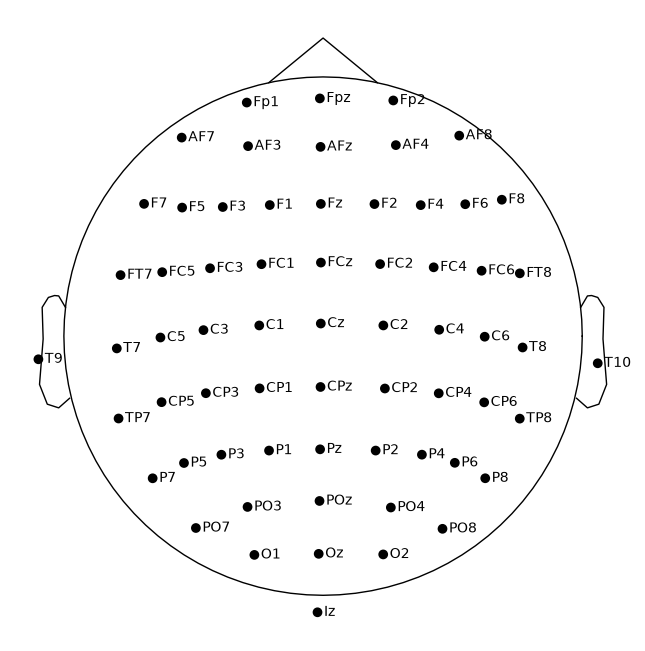

In [23]:
# Visualización de la ubicación de los electrodos
raw2.plot_sensors(show_names=True, sphere=(0.00, 0.02, 0.02, 0.100))
plt.show()

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).


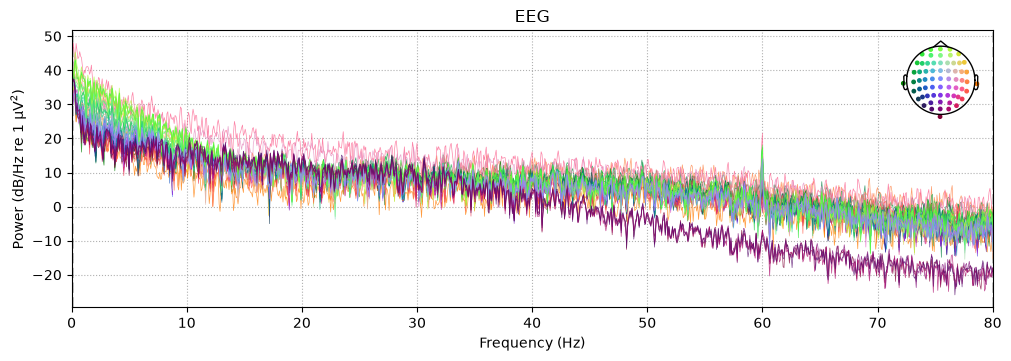

In [24]:
#Calculo PSD
raw2.compute_psd().plot(sphere=(0.00, 0.02, 0.02, 0.100))
plt.show()

Con las localizaciones ubicadas, tambien podemos visualizar la distribución espacial de la potencia espectral  mediante un mapa topográfico o topomap.

Effective window size : 12.800 (s)


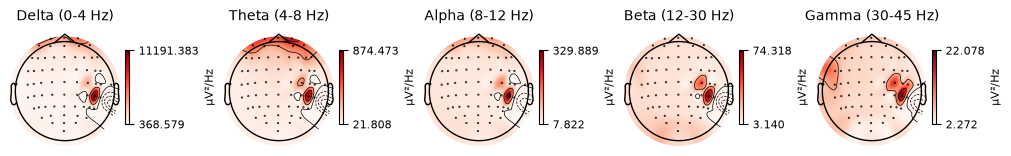

In [25]:
raw2.compute_psd().plot_topomap()
plt.show()

## 2. Preparación para el cuaderno de pre-procesamiento

Hasta este punto trabajamos con la inspección y preparación estructural del registro, sin aplicar filtrado, referencia, interpolación ni ICA. Para que el siguiente cuaderno no dependa del estado de memoria de este Jupyter, guardamos el objeto `Raw` preparado en formato FIF. El formato **FIF** es el formato nativo de MNE y permite volver a cargar un `Raw` conservando atributos importantes del objeto

El segundo cuaderno cargará este archivo como punto de partida.

In [26]:
# Guardamos el Raw preparado para reutilizarlo en el cuaderno de pre-procesamiento.
prepared_path = "results/sample_eeg_prepared-raw.fif"
raw2.save(prepared_path, overwrite=True, verbose=False)

print("Objeto preparado guardado en:", prepared_path)

Objeto preparado guardado en: results/sample_eeg_prepared-raw.fif


**¡Ahora es tiempo de empezar el pre-procesamiento!**

**Referencias**

Luengas, L. A. y Toloza, D. C. (2020). Análisis frecuencial y de la densidad espectral de potencia de la estabilidad de sujetos amputados. *TecnoLógicas, 23*(48), 3-18. https://doi.org/10.22430/22565337.1453

Lou, Z., Wang, R., Belmekki, B. E. Y. y Alouini, M. S. (2026). Towards bioelectric signal-enabled human healthcare monitoring: state-of-the-art, design strategies, challenge, and future. *npj biomedical innovations, 3*(1), 7. https://doi.org/10.1038/s44385-025-00061-

Newman, A. J., Godfrey, D. y Post, R. (2020). *Data Science for Psychology and Neuroscience — in Python*. https://neuraldatascience.io/

Schalk, G. (2009). EEG Motor Movement/Imagery Dataset (RRID:SCR_007345, version 1.0.0). *PhysioNet*. https://doi.org/10.13026/C28G6P



## FIN DEL CUADERNO 1  🧠👨‍💻